In [44]:

import os
import random
import torch
import matplotlib.pyplot as plt

from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from google.colab import drive


In [45]:
# ------------------------------------------------------------
# 1. 設定隨機種子，讓實驗結果較容易重現
# ------------------------------------------------------------

SEED = 42

random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("=" * 60)
print("AI 手寫數字辨識模型訓練開始")
print("=" * 60)

AI 手寫數字辨識模型訓練開始


In [46]:
# ------------------------------------------------------------
# 2. 檢查運算環境
# ------------------------------------------------------------

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("\n[1/8] 運算環境")
print("PyTorch 版本：", torch.__version__)
print("使用裝置：", device)

if torch.cuda.is_available():
    print("GPU 型號：", torch.cuda.get_device_name(0))
else:
    print("目前使用 CPU，訓練速度可能較慢。")
    print("如需 GPU，請在 Colab 設定硬體加速器。")


[1/8] 運算環境
PyTorch 版本： 2.11.0+cu130
使用裝置： cuda
GPU 型號： Tesla T4


In [47]:
# ------------------------------------------------------------
# 3. 掛載 Google Drive
# ------------------------------------------------------------

print("\n[2/8] 連接 Google Drive")

drive.mount("/content/drive")

# 建立專案資料夾
PROJECT_DIR = "/content/drive/MyDrive/MNIST_AI_Project"
MODEL_DIR = os.path.join(PROJECT_DIR, "models")
RESULT_DIR = os.path.join(PROJECT_DIR, "results")

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULT_DIR, exist_ok=True)

print("專案資料夾：", PROJECT_DIR)


[2/8] 連接 Google Drive
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
專案資料夾： /content/drive/MyDrive/MNIST_AI_Project


In [48]:
# ------------------------------------------------------------
# 4. 下載並載入 MNIST 資料集
# ------------------------------------------------------------

print("\n[3/8] 下載與載入資料集")

DATA_DIR = "/content/mnist_data"

transform = transforms.ToTensor()

train_dataset = datasets.MNIST(
    root=DATA_DIR,
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root=DATA_DIR,
    train=False,
    download=True,
    transform=transform
)

BATCH_SIZE = 128

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

print("訓練資料數量：", len(train_dataset))
print("測試資料數量：", len(test_dataset))
print("每批資料數量：", BATCH_SIZE)


[3/8] 下載與載入資料集
訓練資料數量： 60000
測試資料數量： 10000
每批資料數量： 128


In [49]:
# ------------------------------------------------------------
# 5. 建立神經網路
# ------------------------------------------------------------

print("\n[4/8] 建立 AI 模型")


class MNISTModel(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 256),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.network(x)


model = MNISTModel().to(device)

# 損失函數
criterion = nn.CrossEntropyLoss()

# 最佳化器
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print(model)

parameter_count = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("可訓練參數數量：", f"{parameter_count:,}")



[4/8] 建立 AI 模型
MNISTModel(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=256, out_features=128, bias=True)
    (5): ReLU()
    (6): Linear(in_features=128, out_features=10, bias=True)
  )
)
可訓練參數數量： 235,146


In [43]:
# ------------------------------------------------------------
# 6. 訓練模型
# ------------------------------------------------------------

print("\n[5/8] 開始訓練模型")

EPOCHS = 20

history = {
    "loss": [],
    "accuracy": []
}

for epoch in range(EPOCHS):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        # 清除上一輪梯度
        optimizer.zero_grad()

        # 前向傳播
        outputs = model(images)

        # 計算損失
        loss = criterion(outputs, labels)

        # 反向傳播
        loss.backward()

        # 更新模型參數
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = 100.0 * correct / total

    history["loss"].append(epoch_loss)
    history["accuracy"].append(epoch_accuracy)

    print(
        f"Epoch [{epoch + 1}/{EPOCHS}] "
        f"Loss: {epoch_loss:.4f} "
        f"Accuracy: {epoch_accuracy:.2f}%"
    )

print("模型訓練完成！")


[5/8] 開始訓練模型
Epoch [1/20] Loss: 0.3723 Accuracy: 89.28%
Epoch [2/20] Loss: 0.1489 Accuracy: 95.53%
Epoch [3/20] Loss: 0.1054 Accuracy: 96.85%
Epoch [4/20] Loss: 0.0811 Accuracy: 97.55%
Epoch [5/20] Loss: 0.0660 Accuracy: 97.95%
Epoch [6/20] Loss: 0.0558 Accuracy: 98.25%
Epoch [7/20] Loss: 0.0478 Accuracy: 98.47%
Epoch [8/20] Loss: 0.0426 Accuracy: 98.55%
Epoch [9/20] Loss: 0.0358 Accuracy: 98.81%
Epoch [10/20] Loss: 0.0301 Accuracy: 99.03%
Epoch [11/20] Loss: 0.0318 Accuracy: 98.92%
Epoch [12/20] Loss: 0.0277 Accuracy: 99.05%
Epoch [13/20] Loss: 0.0256 Accuracy: 99.14%
Epoch [14/20] Loss: 0.0232 Accuracy: 99.22%
Epoch [15/20] Loss: 0.0219 Accuracy: 99.22%
Epoch [16/20] Loss: 0.0230 Accuracy: 99.24%
Epoch [17/20] Loss: 0.0203 Accuracy: 99.31%
Epoch [18/20] Loss: 0.0186 Accuracy: 99.38%
Epoch [19/20] Loss: 0.0195 Accuracy: 99.32%
Epoch [20/20] Loss: 0.0183 Accuracy: 99.38%
模型訓練完成！


In [50]:
# ------------------------------------------------------------
# 7. 使用測試資料評估模型
# ------------------------------------------------------------

print("\n[6/8] 評估模型")

model.eval()

correct = 0
total = 0
test_loss = 0.0

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        loss = criterion(outputs, labels)

        test_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

test_accuracy = 100.0 * correct / total
average_test_loss = test_loss / total

print("測試資料數量：", total)
print(f"測試損失：{average_test_loss:.4f}")
print(f"測試準確率：{test_accuracy:.2f}%")



[6/8] 評估模型
測試資料數量： 10000
測試損失：2.3050
測試準確率：9.23%


In [51]:
# ------------------------------------------------------------
# 8. 儲存模型與訓練結果
# ------------------------------------------------------------

print("\n[7/8] 儲存模型")

MODEL_PATH = os.path.join(
    MODEL_DIR,
    "mnist_model.pth"
)

torch.save(model.state_dict(), MODEL_PATH)

# 同時儲存訓練參數及評估結果
RESULT_PATH = os.path.join(
    RESULT_DIR,
    "training_results.pt"
)

torch.save(
    {
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "epochs": EPOCHS,
        "test_accuracy": test_accuracy,
        "test_loss": average_test_loss,
        "history": history
    },
    RESULT_PATH
)

print("模型路徑：", MODEL_PATH)
print("訓練結果：", RESULT_PATH)



[7/8] 儲存模型
模型路徑： /content/drive/MyDrive/MNIST_AI_Project/models/mnist_model.pth
訓練結果： /content/drive/MyDrive/MNIST_AI_Project/results/training_results.pt



[8/8] 產生訓練圖表


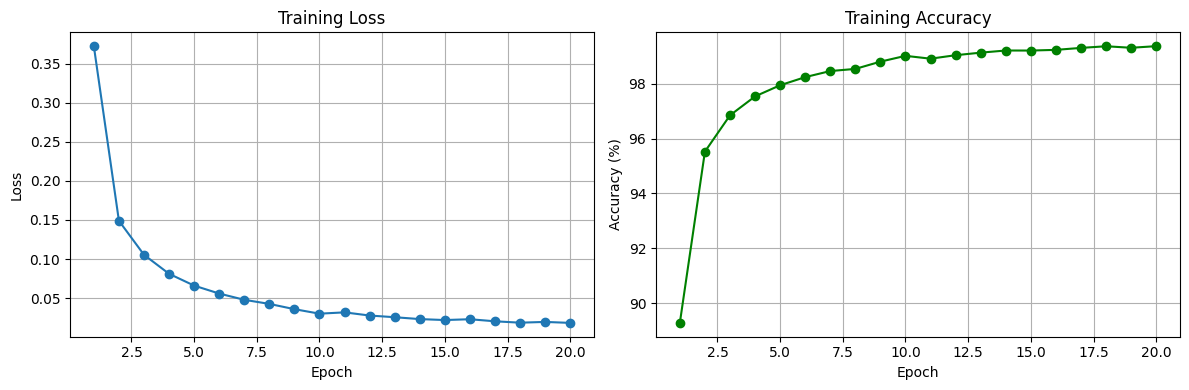

訓練圖表： /content/drive/MyDrive/MNIST_AI_Project/results/training_curves.png


In [52]:
# ------------------------------------------------------------
# 9. 繪製訓練曲線
# ------------------------------------------------------------

print("\n[8/8] 產生訓練圖表")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    range(1, EPOCHS + 1),
    history["loss"],
    marker="o"
)

axes[0].set_title("Training Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].grid(True)

axes[1].plot(
    range(1, EPOCHS + 1),
    history["accuracy"],
    marker="o",
    color="green"
)

axes[1].set_title("Training Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].grid(True)

plt.tight_layout()

FIGURE_PATH = os.path.join(
    RESULT_DIR,
    "training_curves.png"
)

plt.savefig(FIGURE_PATH, dpi=150)
plt.show()

print("訓練圖表：", FIGURE_PATH)



展示 10 張手寫數字辨識結果


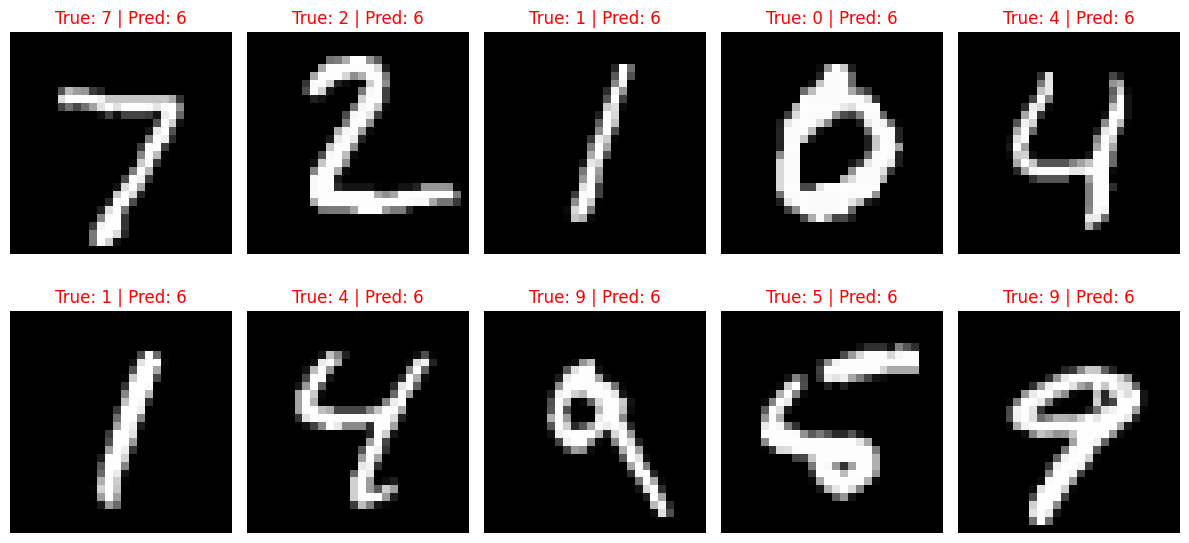


全部流程執行完畢！
最終測試準確率：9.23%
模型檔案： /content/drive/MyDrive/MNIST_AI_Project/models/mnist_model.pth
結果資料夾： /content/drive/MyDrive/MNIST_AI_Project/results
你可以在 Google Drive 中查看已保存的檔案。


In [53]:
# ------------------------------------------------------------
# 10. 顯示模型預測範例
# ------------------------------------------------------------

print("\n展示 10 張手寫數字辨識結果")

model.eval()

images, labels = next(iter(test_loader))

images = images.to(device)
labels = labels.to(device)

with torch.no_grad():
    outputs = model(images[:10])
    predictions = outputs.argmax(dim=1)

images_cpu = images[:10].cpu()
labels_cpu = labels[:10].cpu()
predictions_cpu = predictions.cpu()

fig, axes = plt.subplots(2, 5, figsize=(12, 6))

for i, ax in enumerate(axes.flat):

    ax.imshow(
        images_cpu[i].squeeze(),
        cmap="gray"
    )

    actual = labels_cpu[i].item()
    predicted = predictions_cpu[i].item()

    ax.set_title(
        f"True: {actual} | Pred: {predicted}",
        color="green" if actual == predicted else "red"
    )

    ax.axis("off")

plt.tight_layout()

PREDICTION_PATH = os.path.join(
    RESULT_DIR,
    "prediction_examples.png"
)

plt.savefig(PREDICTION_PATH, dpi=150)
plt.show()

print("\n" + "=" * 60)
print("全部流程執行完畢！")
print("=" * 60)

print(f"最終測試準確率：{test_accuracy:.2f}%")
print("模型檔案：", MODEL_PATH)
print("結果資料夾：", RESULT_DIR)
print("你可以在 Google Drive 中查看已保存的檔案。")